# Lab 8 Walkthrough: Clustering and Regionalization

You will group the 588 Dallas County census tracts by their attributes (clustering), then require each group to be one connected piece of the map (regionalization), and compare the two.

**Data.** American Community Survey (ACS) 2020-2024 5-year estimates for tracts, with 2024 TIGER/Line boundaries. Ten variables per tract are in `data/dallas_tracts_acs2024.gpkg`. Margins of error for children under 5 in poverty are in `data/dallas_u5_poverty.csv`.

**How to use this notebook.** Run it top to bottom. Each part has a short explanation, code, and a **Try it yourself** box that is not graded. The graded work is in `lab8-tasks-solutions.ipynb`.

**Packages.** `geopandas` and `libpysal` (spatial data and weights), `scikit-learn` (scaling, k-means, Ward, scores), `mapclassify` (choropleth classes), `scipy` (connected pieces).

## Part 0. Load the data

`geopandas.read_file` reads the GeoPackage into a GeoDataFrame, a table with one row per tract and a `geometry` column. The coordinate reference system (CRS) is EPSG:32614, UTM zone 14N, which measures in meters, so areas and perimeters computed later are in square meters and meters.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

gdf = gpd.read_file("data/dallas_tracts_acs2024.gpkg")
print(gdf.shape, gdf.crs.to_string())
gdf.head(3)

/tmp/ipykernel_463/2349747411.py:3: DeprecationWarning: Shapely 2.0 is installed, but because PyGEOS is also installed, GeoPandas still uses PyGEOS by default. However, starting with version 0.14, the default will switch to Shapely. To force to use Shapely 2.0 now, you can either uninstall PyGEOS or set the environment variable USE_PYGEOS=0. You can do this before starting the Python process, or in your code before importing geopandas:

import os
os.environ['USE_PYGEOS'] = '0'
import geopandas

In the next release, GeoPandas will switch to using Shapely by default, even if PyGEOS is installed. If you only have PyGEOS installed to get speed-ups, this switch should be smooth. However, if you are using PyGEOS directly (calling PyGEOS functions on geometries from GeoPandas), this will then stop working and you are encouraged to migrate from PyGEOS to Shapely 2.0 (https://shapely.readthedocs.io/en/latest/migration_pygeos.html).
  import geopandas as gpd


(588, 14) EPSG:32614


,GEOID,ALAND,median_house_value,pct_white,pct_hispanic,pct_rented,pct_hh_female,pct_bachelor,median_no_rooms,income_gini,median_age,tt_work,pop_total,geometry
0,48113016638,3449205,420300.0,25.518572,20.501688,65.842167,29.681979,40.048251,4.2,0.4374,48.6,27.664307,2073,"POLYGON ((698187.943 3613912.546, 698236.775 3..."
1,48113013630,292256,230700.0,28.083751,25.261721,86.579491,7.226428,51.539339,3.4,0.3641,36.0,22.172211,2197,"POLYGON ((704710.975 3647157.896, 704727.317 3..."
2,48113012211,1318895,347400.0,7.373370,50.844197,81.978994,20.840243,14.305085,3.7,0.4906,29.8,32.690247,4679,"POLYGON ((715528.594 3631921.330, 715633.903 3..."


The ten variables:

| Variable | Meaning |
|---|---|
| `median_house_value` | Median value of owner-occupied homes, dollars |
| `pct_white` | Percent non-Hispanic white |
| `pct_hispanic` | Percent Hispanic |
| `pct_rented` | Percent of occupied homes that are rented |
| `pct_hh_female` | Percent of households headed by a woman with no partner |
| `pct_bachelor` | Percent of adults 25 and older with a bachelor's degree or more |
| `median_no_rooms` | Median number of rooms per home |
| `income_gini` | Gini index of income inequality (0 equal, 1 unequal) |
| `median_age` | Median age, years |
| `tt_work` | Mean commute time to work, minutes |

In [2]:
VARS = ["median_house_value", "pct_white", "pct_hispanic", "pct_rented", "pct_hh_female",
        "pct_bachelor", "median_no_rooms", "income_gini", "median_age", "tt_work"]
gdf[VARS].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
median_house_value,588.0,391175.18,298977.20,30400.00,224875.00,289700.00,437725.00,2000001.00
pct_white,588.0,29.35,24.28,0.00,10.63,20.90,44.58,94.63
pct_hispanic,588.0,40.00,25.28,0.64,19.01,33.79,62.27,98.41
pct_rented,588.0,42.36,25.74,0.00,21.42,38.23,61.65,98.04
pct_hh_female,588.0,14.92,9.52,0.00,7.34,13.97,20.72,59.19
pct_bachelor,588.0,36.54,25.41,1.58,14.64,29.74,55.94,95.37
median_no_rooms,588.0,5.37,1.37,2.30,4.40,5.30,6.10,10.00
income_gini,588.0,0.41,0.07,0.23,0.36,0.40,0.46,0.68
median_age,588.0,36.06,6.52,19.00,31.48,35.30,40.00,61.60
tt_work,588.0,26.58,5.17,13.41,22.75,26.30,29.92,41.77


**Try it yourself.** Which variable has the largest numbers? Which has the smallest? Keep your answer in mind for Part 2.

## Part 1. Look at the variables on a map

A **choropleth** colors each area by its value. Here `scheme="quantiles"` (from `mapclassify`) sorts tracts into five classes with equal numbers of tracts, and `legend=True` prints the class limits beside the map.

The figure below shows four variables, one per panel, with its own legend.

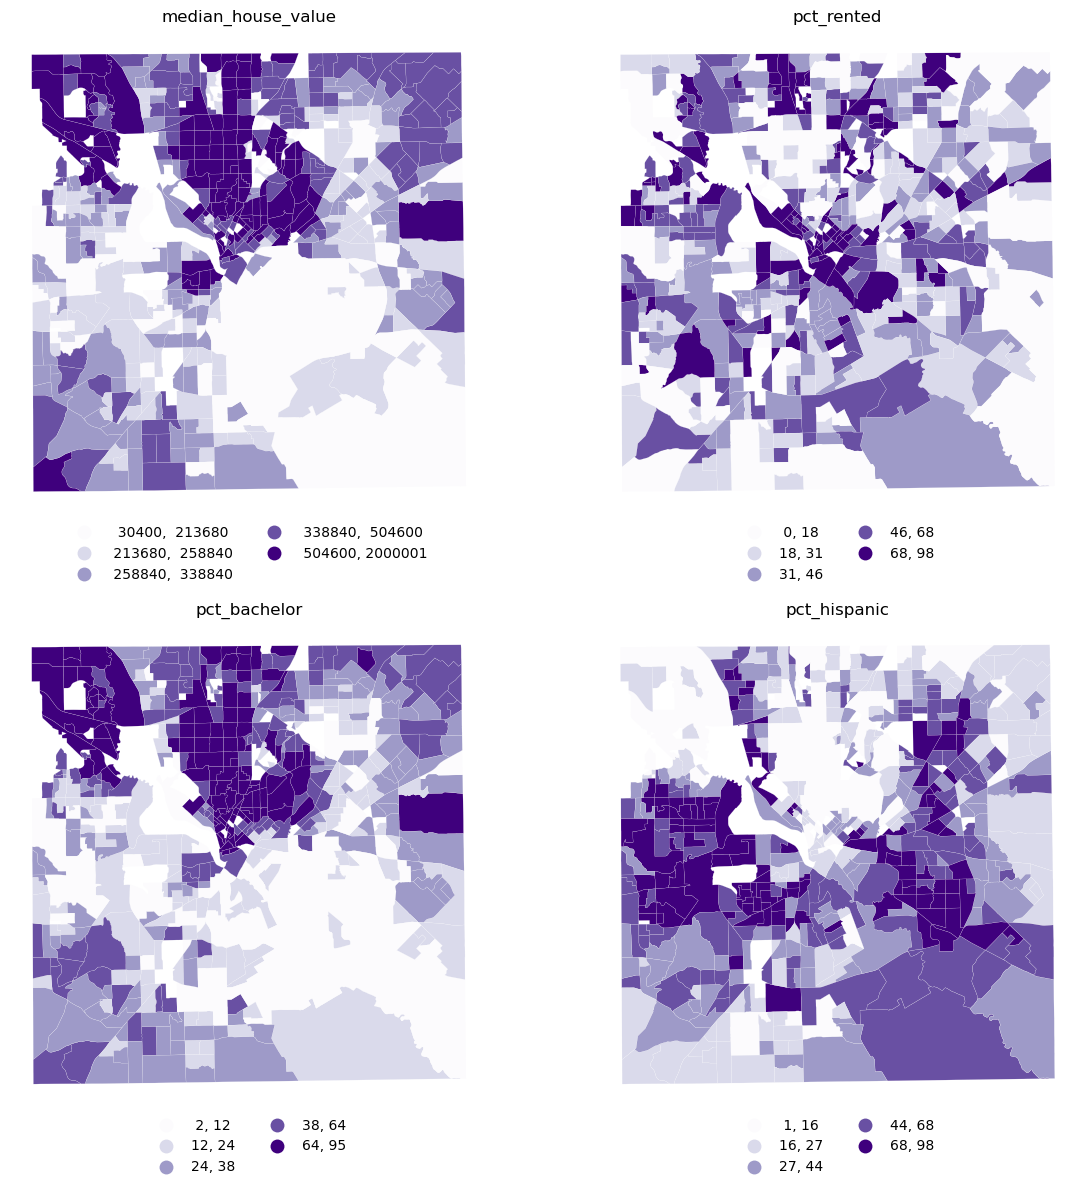

In [3]:
show = ["median_house_value", "pct_rented", "pct_bachelor", "pct_hispanic"]
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for ax, v in zip(axes.ravel(), show):
    gdf.plot(column=v, scheme="quantiles", k=5, cmap="Purples", legend=True, ax=ax,
             edgecolor="white", linewidth=0.1,
             legend_kwds={"loc": "upper center", "bbox_to_anchor": (0.5, 0.0), "ncol": 2, "fmt": "{:.0f}", "frameon": False})
    ax.set_axis_off()
    ax.set_title(v)
plt.tight_layout()
plt.show()

**Try it yourself.** Change `show` to two other variables. Which two maps look most alike? Which look least alike? This is the intuition k-means will turn into numbers.

## Part 2. Standardize before you cluster

K-means and Ward both measure **distance** between tracts. With the raw variables, distance is dominated by whichever variable has the biggest numbers. A $50{,}000$ dollar gap in `median_house_value` is a bigger distance than any possible gap in `pct_rented`, which can differ by at most 100.

**Standardizing** rescales each variable to a common scale. Two common versions:

$$z = \frac{x - \bar{x}}{s} \qquad\qquad r = \frac{x - \tilde{x}}{Q_3 - Q_1}$$

- $x$ is one tract's value of the variable.
- $\bar{x}$ is the mean of the variable and $s$ its standard deviation. The z-score $z$ counts standard deviations from the mean. `sklearn.preprocessing.StandardScaler` computes it.
- $\tilde{x}$ is the median, and $Q_1$ and $Q_3$ are the first and third quartiles (the values below which 25 and 75 percent of tracts fall). $Q_3 - Q_1$ is the interquartile range (IQR). The result $r$ counts IQRs from the median. `sklearn.preprocessing.RobustScaler` computes it.

The median and quartiles barely move when a few extreme tracts are added. The mean and standard deviation do. House values are skewed to the right, so the second version is the safer choice for this data. The plot shows why.

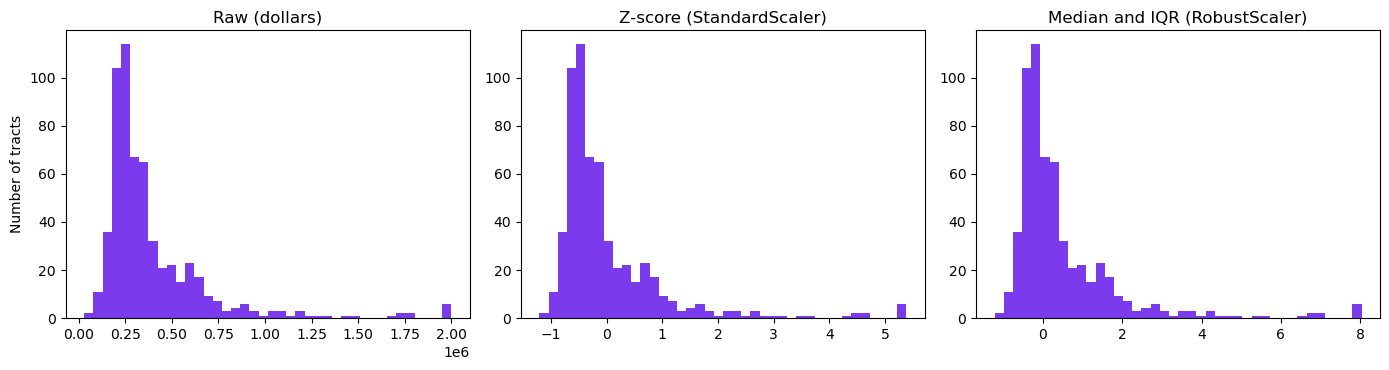

mean, median: 391175.0 289700.0


In [4]:
from sklearn.preprocessing import StandardScaler, RobustScaler

x = gdf[["median_house_value"]]
z = StandardScaler().fit_transform(x)
r = RobustScaler().fit_transform(x)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, vals, name in zip(axes, [x.values, z, r],
                          ["Raw (dollars)", "Z-score (StandardScaler)", "Median and IQR (RobustScaler)"]):
    ax.hist(vals, bins=40, color="#7C3AED")
    ax.set_title(name)
axes[0].set_ylabel("Number of tracts")
plt.tight_layout()
plt.show()
print("mean, median:", x.median_house_value.mean().round(0), x.median_house_value.median().round(0))

The shape is the same in all three panels. Only the scale changes. Now scale all ten variables. `X` is the array every later part uses.

In [5]:
X = RobustScaler().fit_transform(gdf[VARS])
print(X.shape)
pd.DataFrame(X, columns=VARS).describe().round(2).T[["25%", "50%", "75%"]]

(588, 10)


,25%,50%,75%
median_house_value,-0.30,0.0,0.70
pct_white,-0.30,0.0,0.70
pct_hispanic,-0.34,0.0,0.66
pct_rented,-0.42,0.0,0.58
pct_hh_female,-0.50,0.0,0.50
pct_bachelor,-0.37,0.0,0.63
median_no_rooms,-0.53,0.0,0.47
income_gini,-0.44,0.0,0.56
median_age,-0.45,0.0,0.55
tt_work,-0.50,-0.0,0.50


**How much does scaling change who is "close"?** Take one tract and find its 10 nearest tracts using only two variables, once raw and once scaled. `NearestNeighbors` (scikit-learn) returns the closest rows by Euclidean distance.

In [6]:
from sklearn.neighbors import NearestNeighbors

two = ["median_house_value", "pct_rented"]
raw = gdf[two].values
scaled = RobustScaler().fit_transform(gdf[two])

def nearest(data, i, n=10):
    idx = NearestNeighbors(n_neighbors=n + 1).fit(data).kneighbors(data[[i]], return_distance=False)[0]
    return set(idx[1:])            # drop the tract itself

i = 0
shared = len(nearest(raw, i) & nearest(scaled, i))
print(f"Tract {gdf.GEOID[i]}: {shared} of its 10 nearest tracts are the same raw and scaled")

Tract 48113016638: 1 of its 10 nearest tracts are the same raw and scaled


**Try it yourself.** Change `i` to other tracts and rerun. How often do all 10 stay the same? Add `pct_bachelor` to `two` and see whether the answer changes.

## Part 3. K-means

**K-means** (`sklearn.cluster.KMeans`) puts every tract into one of $k$ clusters. You choose $k$. It picks $k$ centers, assigns each tract to its nearest center, moves each center to the mean of its tracts, and repeats until nothing changes. It minimizes

$$\sum_{j=1}^{k} \sum_{i \in C_j} \lVert x_i - u_j \rVert^2$$

- $C_j$ is the set of tracts in cluster $j$.
- $x_i$ is the vector of scaled variables for tract $i$.
- $u_j$ is the mean of cluster $j$ (its center).
- $\lVert x_i - u_j \rVert^2$ is the squared distance from a tract to its center.
- The two sums add that distance over every tract in every cluster. Smaller is tighter.

`n_init=10` runs the algorithm from 10 starting points and keeps the best. `random_state` fixes the starting points so your map matches everyone else's.

In [7]:
PALETTE = ["#7C3AED", "#DB2777", "#2563EB", "#6B6478", "#059669",
           "#F59E0B", "#0EA5E9", "#84CC16", "#EF4444", "#14B8A6"]
COLOR_NAMES = ["purple", "magenta", "blue", "gray", "green",
               "amber", "sky", "lime", "red", "teal"]


def map_clusters(labels, ax, title):
    """Categorical map with one legend entry per cluster (number and color)."""
    labels = np.asarray(labels)
    gdf.plot(color=[PALETTE[i % len(PALETTE)] for i in labels], ax=ax, edgecolor="white", linewidth=0.2)
    ax.set_axis_off()
    ax.set_title(title)
    handles = [Patch(color=PALETTE[i % len(PALETTE)], label=f"{i} ({COLOR_NAMES[i % len(COLOR_NAMES)]})")
               for i in sorted(set(labels))]
    ax.legend(handles=handles, title="Cluster", loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)


def ipq(geoms):
    """Isoperimetric quotient: 4 * pi * area / perimeter^2 (1 = circle)."""
    return 4 * np.pi * geoms.area / geoms.length ** 2

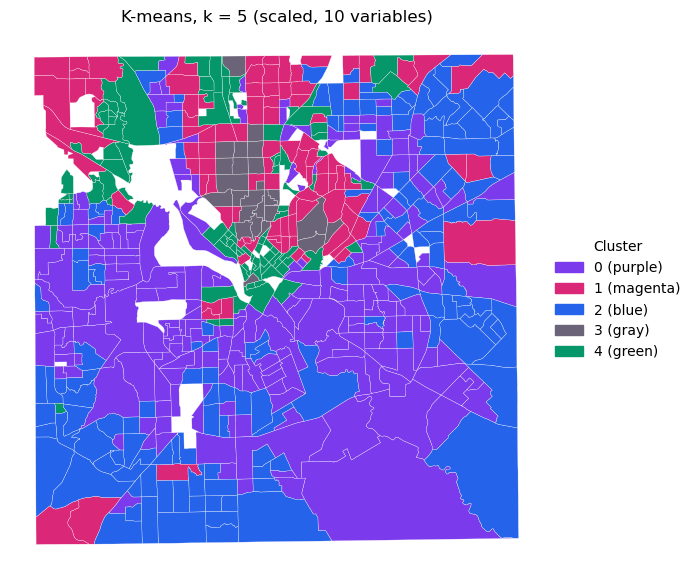

In [8]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X)
gdf["kmeans5"] = km.labels_

fig, ax = plt.subplots(figsize=(8, 7))
map_clusters(gdf["kmeans5"], ax, "K-means, k = 5 (scaled, 10 variables)")
plt.show()

The legend gives each cluster's number and color. The map is the whole answer to "where is each type of tract", but it says nothing about what the types are. That needs a **profile**: the average of each original variable within each cluster.

**Cardinality** is the number of tracts in a cluster. It matters when you need groups of workable size, such as sales territories or school zones, and matters little when you only want types. Land area per cluster is a second size measure: a few large tracts at the edge of the county can hold much of the land.

In [9]:
profile = gdf.groupby("kmeans5")[VARS].mean().round(1)
profile.insert(0, "n_tracts", gdf.groupby("kmeans5").size())
profile.insert(1, "pct_land", (100 * gdf.groupby("kmeans5").ALAND.sum() / gdf.ALAND.sum()).round(1))
profile

,n_tracts,pct_land,median_house_value,pct_white,pct_hispanic,pct_rented,pct_hh_female,pct_bachelor,median_no_rooms,income_gini,median_age,tt_work
kmeans5,,,,,,,,,,,,
0,222,42.6,224571.2,11.8,61.7,48.1,21.6,14.8,4.9,0.4,32.1,28.1
1,98,14.9,580063.3,60.0,17.6,25.9,6.8,65.9,6.5,0.4,42.3,24.0
2,148,31.5,289112.2,23.3,38.3,24.6,16.7,28.7,6.1,0.4,38.4,30.0
3,25,2.9,1497936.2,78.6,8.5,22.5,3.7,82.4,7.7,0.5,44.1,19.1
4,95,8.0,453400.0,35.3,23.3,78.8,8.0,57.2,3.6,0.4,33.3,22.4


Read across a row to name a cluster, for example "high house value, high bachelor's degrees, few renters". Compare `n_tracts` with `pct_land`.

**Try it yourself.** Write a short name for each of the five clusters using the table and the map colors.

### How many clusters? Compare several values of $k$

K-means will return $k$ clusters for any $k$. The same data at $k$ = 2 to 7:

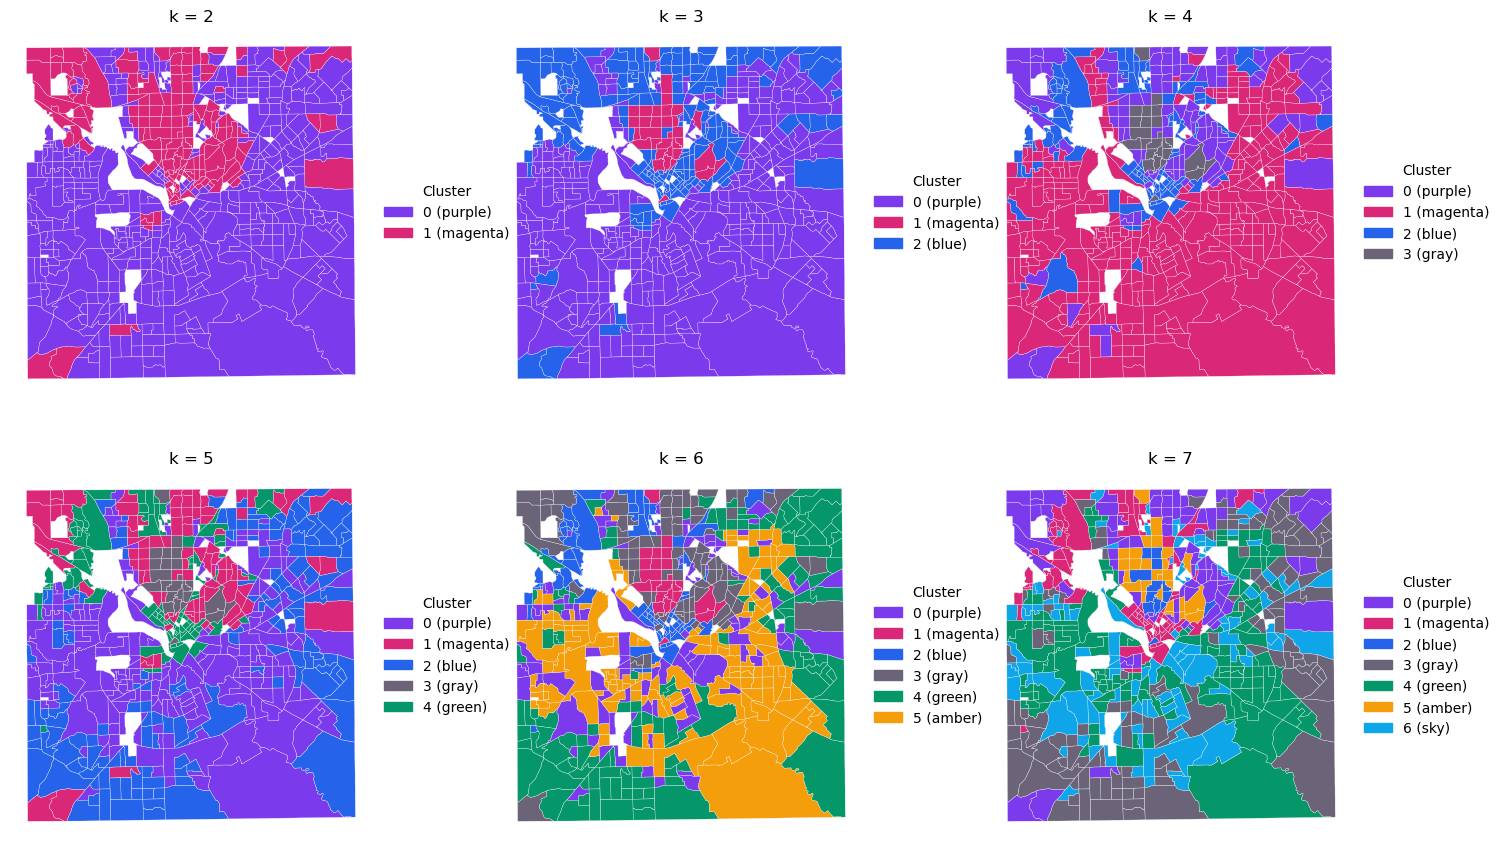

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, k in zip(axes.ravel(), range(2, 8)):
    lab = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    map_clusters(lab, ax, f"k = {k}")
plt.tight_layout()
plt.show()

The **silhouette score** (`sklearn.metrics.silhouette_score`) rates each tract by how much closer it is to its own cluster than to the next nearest cluster, then averages. It runs from -1 to 1. Higher means better separated clusters.

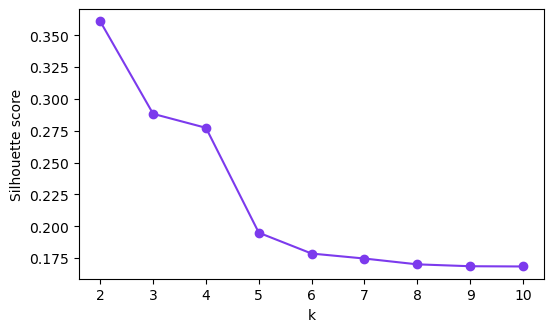

{2: 0.361,
 3: 0.288,
 4: 0.277,
 5: 0.195,
 6: 0.179,
 7: 0.175,
 8: 0.17,
 9: 0.169,
 10: 0.168}

In [11]:
from sklearn.metrics import silhouette_score

ks = list(range(2, 11))
sil = [silhouette_score(X, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)) for k in ks]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ks, sil, marker="o", color="#7C3AED")
ax.set_xlabel("k")
ax.set_ylabel("Silhouette score")
plt.show()
dict(zip(ks, np.round(sil, 3)))

**Try it yourself.** Which $k$ scores highest? Does the best-scoring map also look the most useful to you? A score measures separation in the data, not usefulness for a purpose.

## Part 4. From clusters to regions

**Ward's method** (`sklearn.cluster.AgglomerativeClustering(linkage="ward")`) starts with every tract alone and repeatedly merges the pair of groups whose merger raises the within-group squared distance the least. Stopping at $k$ groups gives $k$ clusters. It optimizes almost the same quantity as k-means but builds the answer bottom-up.

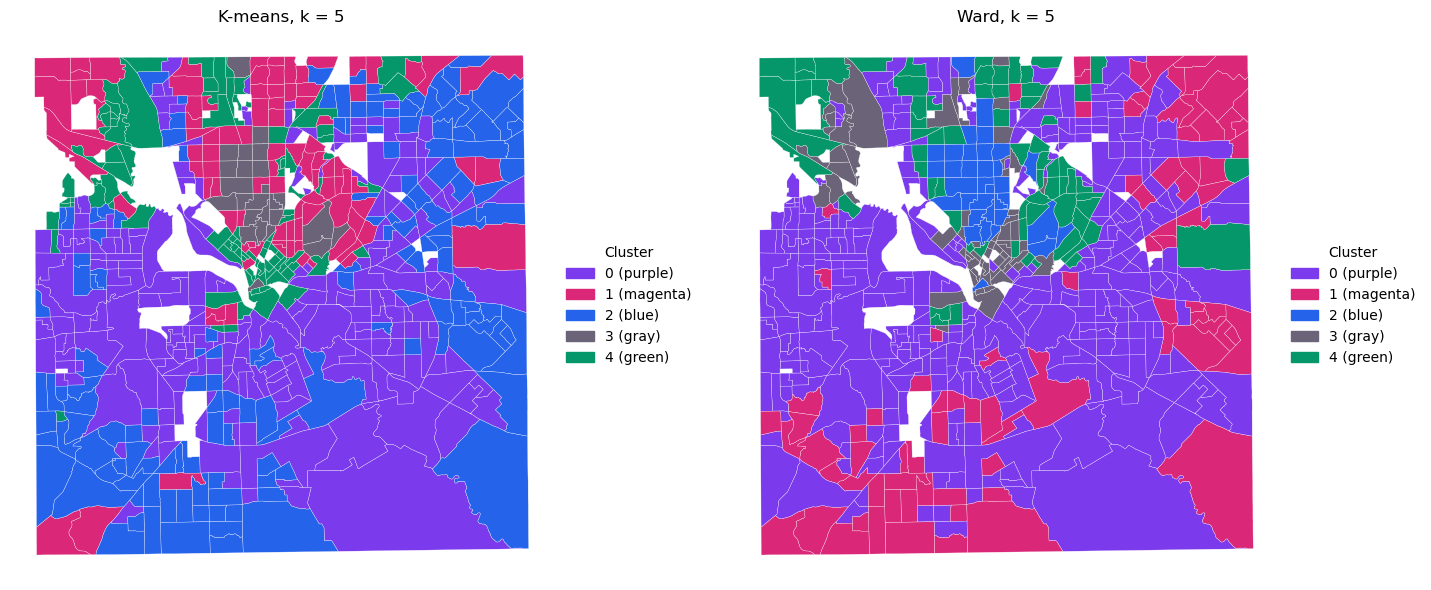

In [12]:
from sklearn.cluster import AgglomerativeClustering

ward = AgglomerativeClustering(n_clusters=5, linkage="ward").fit(X)
gdf["ward5"] = ward.labels_

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
map_clusters(gdf["kmeans5"], axes[0], "K-means, k = 5")
map_clusters(gdf["ward5"], axes[1], "Ward, k = 5")
plt.tight_layout()
plt.show()

The **adjusted mutual information** (`sklearn.metrics.adjusted_mutual_info_score`, AMI) compares two groupings of the same tracts. It is 1 when they agree exactly and about 0 when they agree no more than chance. Cluster numbers do not need to match.

In [13]:
from sklearn.metrics import adjusted_mutual_info_score

print("AMI, k-means vs Ward:", round(adjusted_mutual_info_score(gdf["kmeans5"], gdf["ward5"]), 3))

AMI, k-means vs Ward: 0.584


### The problem: clusters are not connected

A cluster can be made of tracts that are far apart. To count the connected pieces we need to know which tracts touch. A **spatial weights** object stores that. `libpysal.weights.Queen` calls two tracts neighbors if they share a border point or edge. `w.sparse` is the same information as a sparse matrix, and `scipy.sparse.csgraph.connected_components` counts the pieces in a set of tracts.

In [14]:
from libpysal import weights
from scipy.sparse.csgraph import connected_components

w = weights.Queen.from_dataframe(gdf, use_index=False)
print("Components in the whole county:", w.n_components)

def pieces(labels):
    """Number of connected pieces inside each group."""
    out = {}
    for g in sorted(set(labels)):
        mask = np.asarray(labels) == g
        out[g] = connected_components(w.sparse[mask][:, mask])[0]
    return pd.Series(out, name="pieces")

pd.DataFrame({"k-means": pieces(gdf["kmeans5"]), "Ward": pieces(gdf["ward5"])})

Components in the whole county: 1


,k-means,Ward
0,14,14
1,17,17
2,22,5
3,4,14
4,19,15


Any value above 1 means that cluster is split into separate pieces on the map. Every cluster here has more than a dozen.

A **region** is a cluster that is also one connected piece. **Regionalization** is clustering with that constraint. In `AgglomerativeClustering`, passing `connectivity=w.sparse` allows only neighboring groups to merge.

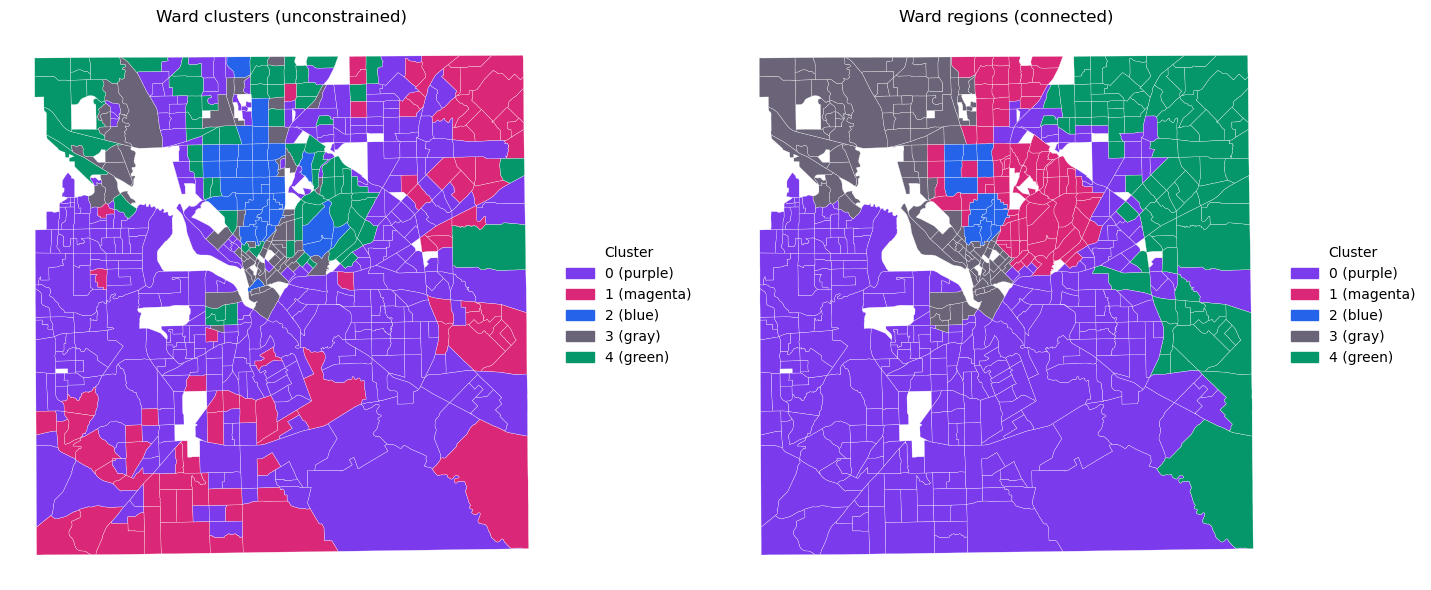

{0: 1, 1: 1, 2: 1, 3: 1, 4: 1}


In [15]:
reg = AgglomerativeClustering(n_clusters=5, linkage="ward", connectivity=w.sparse).fit(X)
gdf["region5"] = reg.labels_

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
map_clusters(gdf["ward5"], axes[0], "Ward clusters (unconstrained)")
map_clusters(gdf["region5"], axes[1], "Ward regions (connected)")
plt.tight_layout()
plt.show()
print(pieces(gdf["region5"]).to_dict())

**Try it yourself.** Change `weights.Queen` to `weights.KNN.from_dataframe(gdf, k=4)` and rerun the cells from `w =` onward. KNN (k nearest neighbors) can leave groups of tracts disconnected from the rest, and scikit-learn will warn you.

### What the constraint costs and buys

**Compactness** is measured by the isoperimetric quotient (IPQ):

$$IPQ = \frac{4 \pi A}{P^2}$$

- $A$ is the area of the shape and $P$ is its perimeter.
- A circle with radius 1 has $A = \pi$ and $P = 2\pi$, so $IPQ = 4\pi^2 / 4\pi^2 = 1$.
- A square with side 1 has $A = 1$ and $P = 4$, so $IPQ = 4\pi/16 = 0.785$.
- A thin sliver has a large $P$ for its $A$, so $IPQ$ is near 0.

**Feature fit** is measured by the Calinski-Harabasz score (`sklearn.metrics.calinski_harabasz_score`). It divides the spread between cluster centers by the spread inside clusters, so higher means tighter, better separated groups.

In [16]:
from sklearn.metrics import calinski_harabasz_score

rows = {}
for name in ["kmeans5", "ward5", "region5"]:
    merged = gdf.dissolve(by=name)            # one (possibly multi-part) shape per group
    rows[name] = {"mean IPQ": ipq(merged.geometry).mean(),
                  "Calinski-Harabasz": calinski_harabasz_score(X, gdf[name])}
pd.DataFrame(rows).T.round(3)

,mean IPQ,Calinski-Harabasz
kmeans5,0.045,217.970
ward5,0.047,180.463
region5,0.115,119.881


The regions are more compact and connected. They fit the attributes less well. Whether that trade is worth it depends on the use.

## Part 5. Margins of error and merging tracts

ACS numbers are estimates from a sample. Each comes with a **margin of error (MOE)**: the 90 percent confidence interval is the estimate plus or minus the MOE. For small groups in small tracts the MOE can be larger than the estimate itself. The file holds the estimate and MOE of children under 5 in poverty (ACS table B17001).

In [17]:
u5 = pd.read_csv("data/dallas_u5_poverty.csv", dtype={"GEOID": str})
g = gdf[["GEOID", "region5"]].merge(u5, on="GEOID")
print("Tracts:", len(g))
print("Share with MOE larger than the estimate:", round((g.moe > g.est).mean(), 2))

Tracts: 588
Share with MOE larger than the estimate: 0.84


Adding estimates over neighboring tracts is exact. Margins of error combine by

$$MOE_{region} = \sqrt{\sum_{i \in R} MOE_i^2}$$

- $R$ is the set of tracts in a region and $MOE_i$ is tract $i$'s margin of error.
- Squaring, adding, and taking the root makes the combined MOE grow more slowly than the estimate.

So the ratio of MOE to estimate shrinks as tracts merge.

In [18]:
reg_tab = g.groupby("region5").agg(n_tracts=("GEOID", "size"), est=("est", "sum"),
                                   moe=("moe", lambda m: np.sqrt((m ** 2).sum())))
reg_tab["moe_over_est"] = (reg_tab.moe / reg_tab.est).round(2)
print("Regions with MOE larger than the estimate:", int((reg_tab.moe > reg_tab.est).sum()), "of", len(reg_tab))
reg_tab

Regions with MOE larger than the estimate: 1 of 5


,n_tracts,est,moe,moe_over_est
region5,,,,
0,297,24193,2119.929952,0.09
1,81,1580,507.630771,0.32
2,14,91,132.348026,1.45
3,112,3635,1070.882813,0.29
4,84,4143,844.867445,0.20


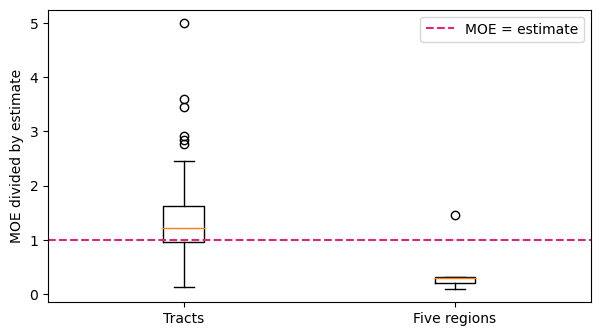

In [19]:
tract_ratio = (g.moe / g.est.replace(0, np.nan)).dropna()
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.boxplot([tract_ratio.clip(upper=5), reg_tab.moe_over_est])
ax.set_xticklabels(["Tracts", "Five regions"])
ax.axhline(1, color="#DB2777", linestyle="--", label="MOE = estimate")
ax.set_ylabel("MOE divided by estimate")
ax.legend()
plt.show()

**Try it yourself.** Use `n_clusters=20` for the regions in Part 4 and rerun Part 5. How many regions still have a MOE larger than the estimate? How many tracts does a reliable estimate seem to need?

## Part 6. K-means does not see space

Shuffle which tract each row of attributes belongs to. The set of points that k-means sees is identical. Only the map changes.

Silhouette, real order:     0.195
Silhouette, shuffled order: 0.197


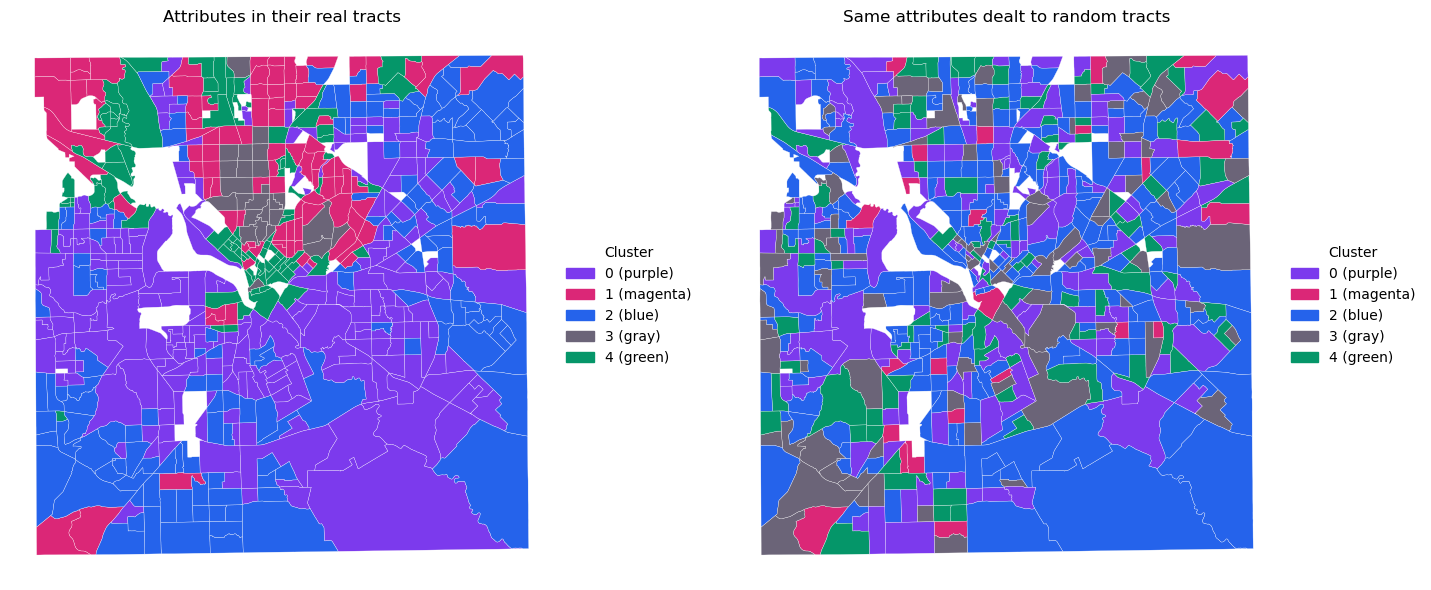

In [20]:
rng = np.random.default_rng(0)
perm = rng.permutation(len(gdf))
X_shuf = X[perm]                               # same rows, dealt to random tracts

km_shuf = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X_shuf)
print("Silhouette, real order:    ", round(silhouette_score(X, km.labels_), 3))
print("Silhouette, shuffled order:", round(silhouette_score(X_shuf, km_shuf.labels_), 3))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
map_clusters(gdf["kmeans5"], axes[0], "Attributes in their real tracts")
map_clusters(km_shuf.labels_, axes[1], "Same attributes dealt to random tracts")
plt.tight_layout()
plt.show()

The score is the same (up to the starting points) and the left map shows structure that the right map lacks. The clusters came from the attributes alone. Geographic patterns on the left come from the data being spatially autocorrelated, not from anything k-means used.

## Learn More / Going Further

- Run `sklearn.cluster.KMeans` on only four variables (income Gini, bachelor's degrees, renters, house value) and compare maps with the ten-variable version.
- Try `sklearn.cluster.AgglomerativeClustering(linkage="average")` and `"single"`. Single linkage often chains many tracts into one cluster.
- Install `spopt` (`pip install spopt`) and try `spopt.region.MaxPHeuristic`, which chooses the number of regions itself subject to a minimum population per region.
- Redistricting extension: build five regions with near-equal `pop_total`. Report IPQ and the ratio of the largest to the smallest region.
- Pick another Texas county from the tract file `slides/week8/data/tl_2024_48_tract.zip` and repeat Parts 3 and 4.

**Sources.** Rey, Arribas-Bel and Wolf (2023), *Geographic Data Science with Python*, "Clustering and Regionalization". Spielman and Folch (2015), "Reducing Uncertainty in the American Community Survey through Data-Driven Regionalization", *PLoS ONE* 10(2): e0115626.